# 03 · Do the explainers tell the truth? A ground-truth benchmark

**Research questions**

* **RQ1 — Faithfulness.** When the true word contributions are known exactly, how close
  do LIME, KernelSHAP, occlusion and feature-space SHAP get, and how many model calls do
  they need?
* **RQ2 — Robustness and agreement.** Are their explanations stable across random seeds
  and under edits the model provably ignores, and how often do explainers disagree?

**Why this is possible here.** Post-hoc explanations are normally evaluated without a
ground truth. Two properties of this project change that: the model is cheap to query,
and titles are short (median ≈ 6 distinct content words after cleaning). We can therefore
enumerate *every* subset of words and compute the **exact Shapley values** of the
word-removal game that LIME and KernelSHAP try to approximate. That turns
“the explanation looks plausible” into a measurable error.

All methods explain the probability of the **predicted** venue, except the two
TF-IDF-space methods (linear SHAP, coefficient × input), which explain log-odds and are
compared with the exact Shapley values of the log-odds.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm notice, irrelevant here

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

from tcner_xai import metrics as M
from tcner_xai import plotting
from tcner_xai.benchmark import BUDGETS, benchmark_title
from tcner_xai.config import RESULTS_DIR, SEED
from tcner_xai.explain import (MAX_EXACT_PLAYERS, FeatureSpaceExplainer, RemovalGame,
                               exact_shapley, explain_anchor, make_anchor_explainer, word_types)
from tcner_xai.model import load_bundle

plotting.set_style()
warnings.filterwarnings("ignore", category=UserWarning)
B = load_bundle()
model, test = B.model, B.test

train=21,497 test=3,373 features=5,000 test accuracy=0.8615


## Benchmark sample

A random sample of 1,000 test titles (fixed seed) with 2 to 14 distinct words: titles
with a single word cannot be ranked, and 14 words keeps the exhaustive enumeration at
≤ 16,384 model calls (under a second) per title.

In [2]:
n_words = test["clean"].map(lambda c: len(word_types(c)))
display(n_words.describe().round(2).to_frame("distinct words per cleaned title"))
eligible = test.index[(n_words >= 2) & (n_words <= MAX_EXACT_PLAYERS - 1)]  # +1 word in the null-word test
print(f"eligible: {len(eligible)}/{len(test)} test titles ({len(eligible) / len(test):.1%})")
N_TITLES = 1000
sample_ids = np.random.default_rng(SEED).choice(eligible, size=N_TITLES, replace=False)
pred_all = model.clf.predict(B.X_test)
print(f"sample: {N_TITLES} titles, of which {(pred_all[sample_ids] != B.y_test[sample_ids]).mean():.1%} misclassified")

,distinct words per cleaned title
count,3373.00
mean,7.09
std,2.17
min,1.00
25%,6.00
50%,7.00
75%,8.00
max,17.00


eligible: 3353/3373 test titles (99.4%)
sample: 1000 titles, of which 14.5% misclassified


## Running the benchmark

Per title: exact Shapley; occlusion; LIME and KernelSHAP at budgets of
16 / 64 / 256 / 1,000 (and LIME's default 5,000) model calls; linear SHAP and
coefficient × input; 5 seeds of LIME and of KernelSHAP at 64 and at 1,000 calls for
stability; and a *null-word* test that inserts the stop word “the” — the vectoriser
removes it, so the prediction is bit-for-bit identical and a continuous explainer should
not change.

In [3]:
fs = FeatureSpaceExplainer(model, B.X_train)
t0 = time.perf_counter()
out = Parallel(n_jobs=-1, verbose=0)(
    delayed(benchmark_title)(model, fs, test.loc[i, "clean"], int(i), seed=0) for i in sample_ids
)
print(f"benchmark finished in {time.perf_counter() - t0:.0f}s")
rows = [r for title_rows in out for r in title_rows]
res = pd.DataFrame([r for r in rows if r["method"] != "stability"])
stab = pd.DataFrame([r for r in rows if r["method"] == "stability"])
res.to_csv(RESULTS_DIR / "benchmark_per_title.csv", index=False)
stab.to_csv(RESULTS_DIR / "benchmark_stability_per_title.csv", index=False)
print(res.shape, stab.shape)

benchmark finished in 166s


(14000, 21) (1000, 23)


## RQ1 · Faithfulness to the exact Shapley values

In [4]:
metric_cols = ["spearman", "top1", "agree@3", "sign@3", "comp@1", "comp@2", "suff@1", "words@80%",
               "seconds", "model_calls"]
summary = (res.groupby(["method", "setting"], sort=False)[metric_cols].mean()
           .round(3).reset_index())
summary.to_csv(RESULTS_DIR / "benchmark_summary.csv", index=False)
display(summary)

,method,setting,spearman,top1,agree@3,sign@3,comp@1,comp@2,suff@1,words@80%,seconds,model_calls
0,Exact Shapley,exact,1.000,1.000,1.000,1.000,0.190,0.311,-0.102,3.491,0.013,391.872
1,Random,-,0.013,0.161,0.486,0.373,0.035,0.076,0.274,4.553,0.000,0.000
2,Occlusion,n+1 calls,0.897,0.922,0.856,0.840,0.192,0.304,-0.091,3.278,0.001,7.985
3,LIME,16,0.769,0.837,0.754,0.724,0.186,0.288,-0.085,3.946,0.049,16.000
4,KernelSHAP,16,0.763,0.757,0.770,0.758,0.177,0.284,-0.053,3.736,0.076,15.680
5,LIME,64,0.933,0.934,0.899,0.877,0.191,0.310,-0.097,3.524,0.053,64.000
6,KernelSHAP,64,0.976,0.959,0.965,0.965,0.190,0.311,-0.100,3.561,0.009,54.144
7,LIME,256,0.953,0.958,0.916,0.897,0.191,0.311,-0.098,3.433,0.069,256.000
8,KernelSHAP,256,0.995,0.985,0.992,0.992,0.190,0.311,-0.102,3.510,0.014,140.736
9,LIME,1000,0.957,0.962,0.922,0.905,0.191,0.312,-0.098,3.421,0.135,1000.000


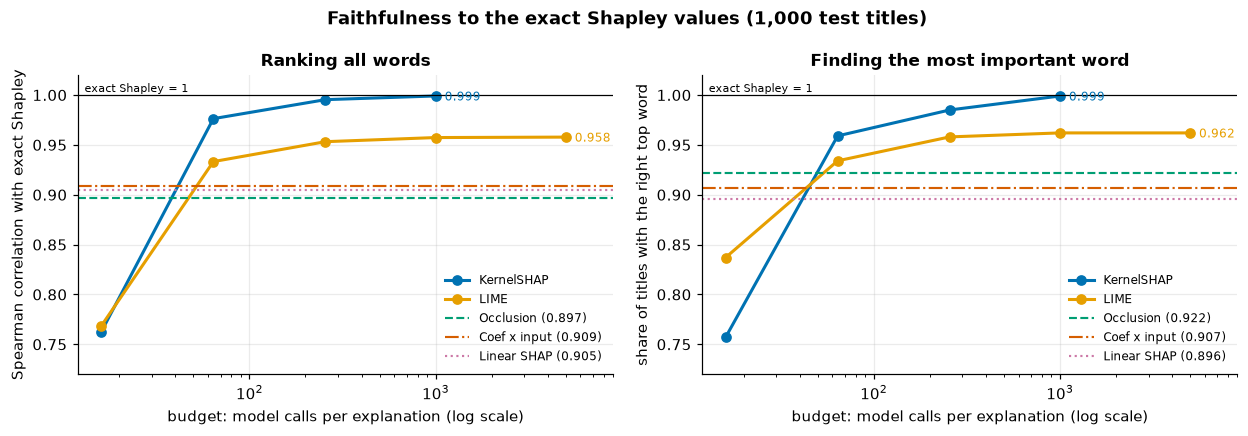

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
metrics_shown = [("spearman", "Spearman correlation with exact Shapley", "Ranking all words"),
                 ("top1", "share of titles with the right top word", "Finding the most important word")]
for ax, (col, ylab, title) in zip(axes, metrics_shown):
    for name in ["KernelSHAP", "LIME"]:
        d = res[res["method"] == name].groupby("setting")[col].mean()
        d.index = d.index.astype(int)
        d = d.sort_index()
        ax.plot(d.index, d.values, "o-", lw=2, label=name, color=plotting.METHOD_COLORS[name])
        ax.annotate(f"{d.values[-1]:.3f}", (d.index[-1], d.values[-1]), textcoords="offset points",
                    xytext=(6, -3), fontsize=8, color=plotting.METHOD_COLORS[name])
    refs = [("Occlusion", "--"), ("Coef x input", "-."), ("Linear SHAP", ":")]
    for name, style in refs:
        v = res[res["method"] == name][col].mean()
        ax.axhline(v, ls=style, lw=1.4, color=plotting.METHOD_COLORS[name], label=f"{name} ({v:.3f})")
    ax.axhline(1.0, color="black", lw=0.8)
    ax.text(13, 1.003, "exact Shapley = 1", fontsize=7.5)
    ax.set_xscale("log")
    ax.set_xlim(12, 9000)
    ax.set_ylim(0.72, 1.02)
    ax.set_xlabel("budget: model calls per explanation (log scale)")
    ax.set_ylabel(ylab)
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle(f"Faithfulness to the exact Shapley values ({N_TITLES:,} test titles)", fontweight="bold")
fig.tight_layout()
plotting.save(fig, "03_faithfulness_vs_budget")
plt.show()

**Comprehensiveness** (DeYoung et al., 2020): delete the *k* words an explainer ranks
highest and measure how much the probability of the predicted venue drops. A faithful
explainer removes the words that matter, so higher is better; the exact Shapley ranking
and a random ranking bracket what is achievable.

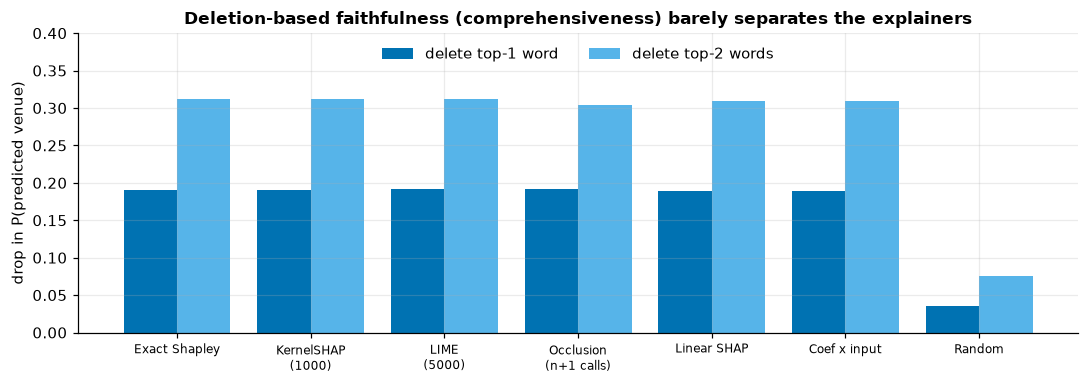

In [6]:
pick = [("Exact Shapley", "exact"), ("KernelSHAP", 1000), ("LIME", 5000), ("Occlusion", "n+1 calls"),
        ("Linear SHAP", "closed form"), ("Coef x input", "closed form"), ("Random", "-")]
labels, comp1, comp2 = [], [], []
for m, s in pick:
    d = res[(res["method"] == m) & (res["setting"].astype(str) == str(s))]
    labels.append(f"{m}\n({s})" if s not in ("exact", "-", "closed form") else m)
    comp1.append(d["comp@1"].mean())
    comp2.append(d["comp@2"].mean())
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(labels))
ax.bar(x - 0.2, comp1, 0.4, label="delete top-1 word", color="#0072B2")
ax.bar(x + 0.2, comp2, 0.4, label="delete top-2 words", color="#56B4E9")
ax.set_xticks(x, labels, fontsize=8)
ax.set_ylabel("drop in P(predicted venue)")
ax.set_ylim(0, 0.4)
ax.set_title("Deletion-based faithfulness (comprehensiveness) barely separates the explainers")
ax.legend(loc="upper center", ncol=2)
fig.tight_layout()
plotting.save(fig, "03_comprehensiveness")
plt.show()

## RQ2 · Disagreement between explainers

Krishna et al. (2022) call it the *disagreement problem*: different explainers give
different answers for the same prediction, and practitioners resolve this ad hoc. Here
we can say who is right. Each cell is the mean pairwise Spearman correlation between
two methods' word rankings over the same titles.

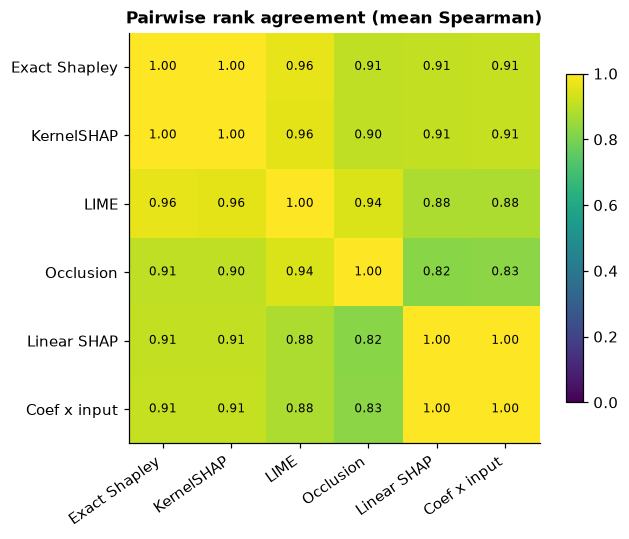

In [7]:
methods = {"Exact Shapley": "exact", "KernelSHAP": "1000", "LIME": "5000", "Occlusion": "n+1 calls",
           "Linear SHAP": "closed form", "Coef x input": "closed form"}

# recompute raw attribution vectors for a subset to build the pairwise matrix
from tcner_xai.explain import kernel_shap, lime_explain, occlusion

sub = sample_ids[:300]
vecs = {m: [] for m in methods}
for i in sub:
    clean = test.loc[i, "clean"]
    g = RemovalGame(model, clean)
    gt = exact_shapley(g)
    k = int(np.argmax(gt["v_full"]))
    vecs["Exact Shapley"].append(gt["proba"][:, k])
    vecs["KernelSHAP"].append(kernel_shap(g, [k], nsamples=1000, seed=0)[k])
    vecs["LIME"].append(lime_explain(model, clean, [k], num_samples=5000, seed=0)[0][k])
    vecs["Occlusion"].append(occlusion(g)["proba"][:, k])
    vecs["Linear SHAP"].append(fs.explain(clean, "linear_shap")["logit"][:, k])
    vecs["Coef x input"].append(fs.explain(clean, "coef_x_input")["logit"][:, k])

names = list(methods)
agree = np.zeros((len(names), len(names)))
for a, ma in enumerate(names):
    for b, mb in enumerate(names):
        agree[a, b] = np.nanmean([M.rank_corr(x, y) for x, y in zip(vecs[ma], vecs[mb])])
agree_df = pd.DataFrame(agree, index=names, columns=names).round(3)
agree_df.to_csv(RESULTS_DIR / "benchmark_pairwise_agreement.csv")

fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(agree, cmap="viridis", vmin=0, vmax=1)
for a in range(len(names)):
    for b in range(len(names)):
        ax.text(b, a, f"{agree[a, b]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if agree[a, b] < 0.6 else "black")
ax.set_xticks(range(len(names)), names, rotation=35, ha="right")
ax.set_yticks(range(len(names)), names)
ax.grid(False)
ax.set_title("Pairwise rank agreement (mean Spearman)")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plotting.save(fig, "03_pairwise_agreement")
plt.show()

## RQ2 · Stability across seeds and continuity under a null edit

In [8]:
stab_summary = stab.drop(columns=["title_id", "n_words", "pred", "p_pred", "method"]).mean().round(3)
stab_summary.to_csv(RESULTS_DIR / "benchmark_stability_summary.csv", header=["value"])
display(stab_summary.to_frame("mean over titles"))

,mean over titles
LIME@64 top3 jaccard,0.843
LIME@64 spearman,0.921
LIME@64 rel. std,0.154
KernelSHAP@64 top3 jaccard,0.920
KernelSHAP@64 spearman,0.960
KernelSHAP@64 rel. std,0.074
LIME@1000 top3 jaccard,0.956
LIME@1000 spearman,0.978
LIME@1000 rel. std,0.036
KernelSHAP@1000 top3 jaccard,0.997


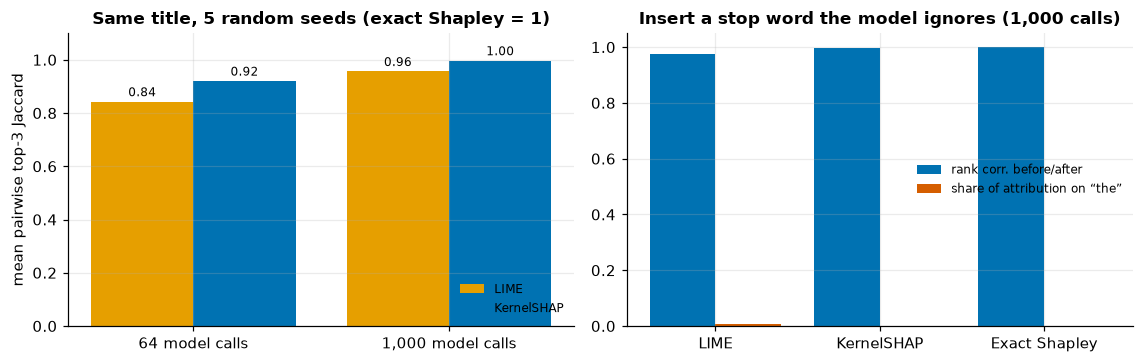

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
x = np.arange(2)
for off, name in [(-0.2, "LIME"), (0.2, "KernelSHAP")]:
    vals = [stab[f"{name}@{b} top3 jaccard"].mean() for b in (64, 1000)]
    axes[0].bar(x + off, vals, 0.4, label=name, color=plotting.METHOD_COLORS[name])
    for xi, v in zip(x + off, vals):
        axes[0].text(xi, v + 0.02, f"{v:.2f}", ha="center", fontsize=8)
axes[0].set_xticks(x, ["64 model calls", "1,000 model calls"])
axes[0].set_ylim(0, 1.1)
axes[0].set_ylabel("mean pairwise top-3 Jaccard")
axes[0].set_title("Same title, 5 random seeds (exact Shapley = 1)")
axes[0].legend(fontsize=8, loc="lower right")
cont = [stab[f"{m} continuity spearman"].mean() for m in ["LIME", "KernelSHAP", "Exact Shapley"]]
null = [stab[f"{m} null-word share"].mean() for m in ["LIME", "KernelSHAP", "Exact Shapley"]]
x = np.arange(3)
axes[1].bar(x - 0.2, cont, 0.4, label="rank corr. before/after", color="#0072B2")
axes[1].bar(x + 0.2, null, 0.4, label="share of attribution on “the”", color="#D55E00")
axes[1].set_xticks(x, ["LIME", "KernelSHAP", "Exact Shapley"])
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Insert a stop word the model ignores (1,000 calls)")
axes[1].legend(fontsize=8, loc="center right")
fig.tight_layout()
plotting.save(fig, "03_stability_continuity")
plt.show()

## Completeness, contrastivity and compactness

In [10]:
extra = (res.groupby(["method", "setting"], sort=False)[["efficiency_gap", "lime_r2", "contrast_spearman",
                                                          "absent_share", "words@80%"]]
         .mean().round(3).dropna(how="all").reset_index())
extra.to_csv(RESULTS_DIR / "benchmark_extra.csv", index=False)
display(extra)

,method,setting,efficiency_gap,lime_r2,contrast_spearman,absent_share,words@80%
0,Exact Shapley,exact,0.000,NaN,-0.681,NaN,3.491
1,Random,-,NaN,NaN,NaN,NaN,4.553
2,Occlusion,n+1 calls,NaN,NaN,-0.732,NaN,3.278
3,LIME,16,0.283,0.742,-0.685,NaN,3.946
4,KernelSHAP,16,0.000,NaN,-0.591,NaN,3.736
5,LIME,64,0.223,0.852,-0.700,NaN,3.524
6,KernelSHAP,64,0.000,NaN,-0.679,NaN,3.561
7,LIME,256,0.191,0.856,-0.705,NaN,3.433
8,KernelSHAP,256,0.000,NaN,-0.679,NaN,3.510
9,LIME,1000,0.178,0.854,-0.704,NaN,3.421


* **Efficiency gap** — Shapley values sum exactly to P(full title) − P(empty title);
  LIME's weights do not, so their sum cannot be read as “how much of the prediction
  is explained”.
* **LIME local R²** — how well LIME's linear surrogate fits the model on its own samples.
* **Contrast Spearman** — rank correlation between the explanation for the predicted
  venue and for the runner-up. Lower = the explanation is more specific to the decision.
* **Absent share** — for linear SHAP, the share of attribution assigned to n-grams that
  are not in the title (see notebook 02).

## Anchors

Anchors are rules, not scores, so we evaluate them differently: *precision* and
*coverage* as reported by alibi, *consistency* across seeds, rule length, and whether the
rule contains the word with the highest exact Shapley value. We also re-check precision
with the removal perturbation used everywhere else (alibi replaces words by `UNK`, which
also breaks bigrams) and — more importantly — on **real test titles**: alibi's coverage
is measured on its own perturbation samples, so it does not say how many real titles a
rule applies to.

In [11]:
from tcner_xai.explain import anchor_dataset_stats

N_ANCHOR = 60
anchor_ids = sample_ids[:N_ANCHOR]
test_pred = model.clf.predict_proba(B.X_test).argmax(1)
explainers = {s: make_anchor_explainer(model, seed=s) for s in (0, 1, 2)}
rng = np.random.default_rng(SEED)
arows = []
for i in anchor_ids:
    clean = test.loc[i, "clean"]
    g = RemovalGame(model, clean)
    gt = exact_shapley(g)
    k = int(np.argmax(gt["v_full"]))
    runs = [explain_anchor(explainers[s], clean) for s in (0, 1, 2)]
    a = runs[0]
    in_anchor = np.array([w in a["anchor"] for w in g.players])
    masks = rng.random((500, g.n)) < 0.5
    masks[:, in_anchor] = True
    removal_precision = float((g(masks)[0].argmax(1) == k).mean())
    ds = anchor_dataset_stats(a["anchor"], test["clean"], test_pred, k)
    arows.append({
        "title_id": int(i), "n_words": g.n, "anchor": " AND ".join(a["anchor"]),
        "length": len(a["anchor"]), "precision": a["precision"], "coverage": a["coverage"],
        "removal precision": removal_precision,
        "test-set coverage": ds["data coverage"], "test-set precision": ds["data precision"],
        "contains GT top word": g.players[int(np.argmax(gt["proba"][:, k]))] in a["anchor"],
        "same rule across 3 seeds": len({tuple(sorted(r["anchor"])) for r in runs}) == 1,
        "seed jaccard": M.mean_pairwise([set(r["anchor"]) for r in runs], M.jaccard),
        "seconds": a["seconds"],
    })
anchors = pd.DataFrame(arows)
anchors["predicted"] = model.classes_[test_pred[anchors["title_id"]]]
anchors.to_csv(RESULTS_DIR / "anchors_per_title.csv", index=False)
nonempty = anchors[anchors["length"] > 0]
anchor_summary = nonempty.drop(columns=["title_id", "anchor", "predicted"]).mean(numeric_only=True).round(3)
anchor_summary["share of empty anchors"] = round(float((anchors["length"] == 0).mean()), 3)
anchor_summary["same rule across 3 seeds"] = round(float(anchors["same rule across 3 seeds"].mean()), 3)
print("Empty anchors (the prediction holds whatever words are removed) by predicted venue:")
print(anchors[anchors["length"] == 0]["predicted"].value_counts().to_string())
print("\nMeans below are over the non-empty rules:")
anchor_summary.to_csv(RESULTS_DIR / "anchors_summary.csv", header=["value"])
display(anchor_summary.to_frame("mean"))
display(anchors.head(10))

Empty anchors (the prediction holds whatever words are removed) by predicted venue:
predicted
ISCAS    17

Means below are over the non-empty rules:


,mean
n_words,6.884
length,1.233
precision,0.999
coverage,0.448
removal precision,0.996
test-set coverage,0.023
test-set precision,0.845
contains GT top word,0.744
same rule across 3 seeds,0.900
seed jaccard,0.957


,title_id,n_words,anchor,length,precision,coverage,removal precision,test-set coverage,test-set precision,contains GT top word,same rule across 3 seeds,seed jaccard,seconds,predicted
0,2044,5,datum,1,1.0,0.5021,1.0,0.056033,0.444444,True,True,1.000000,0.062461,VLDB
1,1989,7,algorithm,1,1.0,0.5085,1.0,0.066113,0.784753,False,True,1.000000,0.064906,ISCAS
2,1291,5,high,1,1.0,0.4976,1.0,0.047732,0.906832,True,True,1.000000,0.055887,ISCAS
3,1749,3,molecular AND link AND communication,3,1.0,0.1342,1.0,0.000296,1.000000,True,True,1.000000,0.097735,INFOCOM
4,1142,7,filter,1,1.0,0.5013,1.0,0.102579,0.988439,True,True,1.000000,0.076447,ISCAS
5,755,7,neural,1,1.0,0.5082,1.0,0.043581,0.993197,True,True,1.000000,0.067932,ISCAS
6,2681,7,number,1,1.0,0.4951,1.0,0.005040,0.882353,False,False,0.333333,0.078053,ISCAS
7,370,6,network,1,1.0,0.5079,1.0,0.125111,0.497630,True,True,1.000000,0.062203,INFOCOM
8,639,7,signal,1,1.0,0.5055,1.0,0.032315,0.972477,False,True,1.000000,0.065117,ISCAS
9,1073,6,current,1,1.0,0.4934,1.0,0.035280,0.991597,False,True,1.000000,0.058651,ISCAS


## Take-aways

(Numbers are from the run saved in this notebook; see `results/benchmark_summary.csv`.)

1. **KernelSHAP converges to the truth; LIME plateaus.** Both see the same kind of
   perturbed titles, but LIME fits a *kernel-weighted linear* model whose weights are not
   Shapley values. At tiny budgets (≤ 64 calls) LIME is competitive, but beyond that more
   samples make it more *stable* (seed Jaccard ≈ 0.96) without making it more *faithful*:
   its rank correlation with the truth stops at ≈ 0.96 and it names the wrong top word
   for ≈ 4% of titles even at its default 5,000 samples. KernelSHAP reaches ≈ 0.999.
2. **On short texts the exact answer is cheaper than the approximation.** Exact Shapley
   needs on average a few hundred model calls (≈ 0.01 s), far less than LIME's default
   5,000 calls (≈ 0.5 s).
3. **Occlusion and the original feature-space SHAP are good but not exact** (rank
   correlation ≈ 0.90, wrong top word for ≈ 8–10% of titles). Feature-space SHAP also
   puts ≈ 46% of its attribution on n-grams that are absent from the title.
4. **Removal-based faithfulness metrics barely separate the methods**: deleting the
   top-1 word lowers the predicted probability by ≈ 0.19 for every method (random: 0.04).
   The methods agree on the dominant word and differ in the tail, which deletion
   metrics cannot see — a ground truth can.
5. **Anchors** are short and precise *inside their own sampling distribution*, but their
   precision on real titles that contain the rule's words is much lower (table above).